# VAE-GAN

Combine a probabilistic encoder and reconstruction plus KL objectives with an image discriminator that encourages realistic reconstructions. Adversarial training can be unstable and requires loss balancing.

This standalone notebook includes its own MNIST setup, model components, objective, and training step. Run the cells from top to bottom. The training cell runs 50 epochs on the full MNIST training split. A GPU runtime is recommended in Colab.

## Shared MNIST data and VAE components

The baseline is a small MLP VAE with a diagonal Gaussian posterior and Bernoulli image decoder. We reuse it where the variant changes the objective rather than the architecture.

In [3]:
import math
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

class MLPVAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__(); self.latent_dim = latent_dim
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.mu = nn.Linear(400, latent_dim); self.logvar = nn.Linear(400, latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 400), nn.ReLU(), nn.Linear(400, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x.flatten(1)); return self.mu(h), self.logvar(h)
    def reparameterize(self, mu, logvar):
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x); z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_terms(recon, x, mu, logvar):
    rec = F.binary_cross_entropy(recon, x, reduction='none').flatten(1).sum(1).mean()
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(1).mean()
    return rec, kl

def sample_batch(loader):
    return next(iter(loader))[0].to(device)

Using device: cuda


## Implementation

The following cell defines this variant's model-specific objective and optimization step.

## 7. VAE-GAN

VAE-GAN combines a probabilistic encoder and reconstruction objective with adversarial realism. The discriminator below distinguishes real MNIST images from reconstructions. The VAE minimizes reconstruction BCE, KL, and an adversarial term that asks the discriminator to classify reconstructions as real. A pixel loss plus an adversarial loss is a simple variant; some VAE-GANs also use discriminator features for perceptual reconstruction. Adversarial training needs careful balancing and can be unstable.

In [5]:
class ImageDiscriminator(nn.Module):
    def __init__(self):
        super().__init__(); self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.LeakyReLU(.2), nn.Linear(256, 1))
    def forward(self, x): return self.net(x)

vae_gan = MLPVAE().to(device); image_disc = ImageDiscriminator().to(device)
vg_optim = torch.optim.Adam(vae_gan.parameters(), lr=1e-3); image_disc_optim = torch.optim.Adam(image_disc.parameters(), lr=1e-3)

def vaegan_train_step(x, beta=1.0, adversarial_weight=0.1):
    vae_gan.train(); image_disc.train()
    x = x.to(device); recon, mu, logvar = vae_gan(x); rec, kl = vae_terms(recon, x, mu, logvar)
    # Update discriminator using detached reconstructions.
    real_logits = image_disc(x); fake_logits = image_disc(recon.detach())
    d_loss = F.binary_cross_entropy_with_logits(real_logits, torch.ones_like(real_logits)) + F.binary_cross_entropy_with_logits(fake_logits, torch.zeros_like(fake_logits))
    image_disc_optim.zero_grad(); d_loss.backward(); image_disc_optim.step()
    # Update encoder/decoder to reconstruct and fool the discriminator.
    # Freeze discriminator weights, while still allowing gradients into the generated image.
    for parameter in image_disc.parameters():
        parameter.requires_grad_(False)
    fake_logits = image_disc(recon)
    adv = F.binary_cross_entropy_with_logits(fake_logits, torch.ones_like(fake_logits))
    loss = rec + beta * kl + adversarial_weight * adv
    vg_optim.zero_grad(); loss.backward(); vg_optim.step()
    for parameter in image_disc.parameters():
        parameter.requires_grad_(True)
    return {'reconstruction': rec.item(), 'kl': kl.item(), 'adversarial': adv.item(), 'discriminator': d_loss.item()}

# Example: metrics = vaegan_train_step(sample_batch(train_loader))

## Full training — 50 epochs

Train on the full MNIST training split. In Colab, use a GPU runtime if available. The checkpoint stores the VAE, discriminator, optimizer states, and epoch metrics.

In [6]:
from pathlib import Path

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    totals = {}
    for images, _ in train_loader:
        batch_metrics = vaegan_train_step(images)
        for name, value in batch_metrics.items():
            totals[name] = totals.get(name, 0.0) + float(value) * images.size(0)
    epoch_metrics = {name: value / len(train_loader.dataset) for name, value in totals.items()}
    history.append(epoch_metrics)
    if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
        summary = " | ".join(f"{name}={value:.4f}" for name, value in epoch_metrics.items())
        print(f"Epoch {epoch:02d}/{epochs} | {summary}")

checkpoint = {
    "vae": vae_gan.state_dict(),
    "discriminator": image_disc.state_dict(),
    "vae_optimizer": vg_optim.state_dict(),
    "discriminator_optimizer": image_disc_optim.state_dict(),
    "epochs": epochs,
    "history": history,
}
checkpoint_path = Path("15_VAE_GAN_50_epochs.pt")
torch.save(checkpoint, checkpoint_path)
print(f"Saved checkpoint to {checkpoint_path.resolve()}")


Epoch 01/50 | reconstruction=147.0754 | kl=15.5003 | adversarial=1.2131 | discriminator=0.9570
Epoch 05/50 | reconstruction=87.7038 | kl=22.8539 | adversarial=2.5469 | discriminator=0.4146
Epoch 10/50 | reconstruction=83.4267 | kl=23.5357 | adversarial=3.3403 | discriminator=0.3068
Epoch 15/50 | reconstruction=81.6002 | kl=23.7813 | adversarial=4.0032 | discriminator=0.2420
Epoch 20/50 | reconstruction=80.5098 | kl=23.9569 | adversarial=4.5131 | discriminator=0.2033
Epoch 25/50 | reconstruction=79.6981 | kl=24.0168 | adversarial=4.9189 | discriminator=0.1989
Epoch 30/50 | reconstruction=79.1172 | kl=24.0776 | adversarial=5.2627 | discriminator=0.1866
Epoch 35/50 | reconstruction=78.6514 | kl=24.0975 | adversarial=5.5134 | discriminator=0.1720
Epoch 40/50 | reconstruction=78.2043 | kl=24.1561 | adversarial=5.7697 | discriminator=0.1774
Epoch 45/50 | reconstruction=77.8997 | kl=24.1771 | adversarial=5.9906 | discriminator=0.1628
Epoch 50/50 | reconstruction=77.6397 | kl=24.1772 | adversa

## Review training losses

The VAE-GAN balances reconstruction and KL with an adversarial term. The discriminator has its own loss. These curves use different scales, so inspect each separately; adversarial losses can oscillate even when training is progressing.

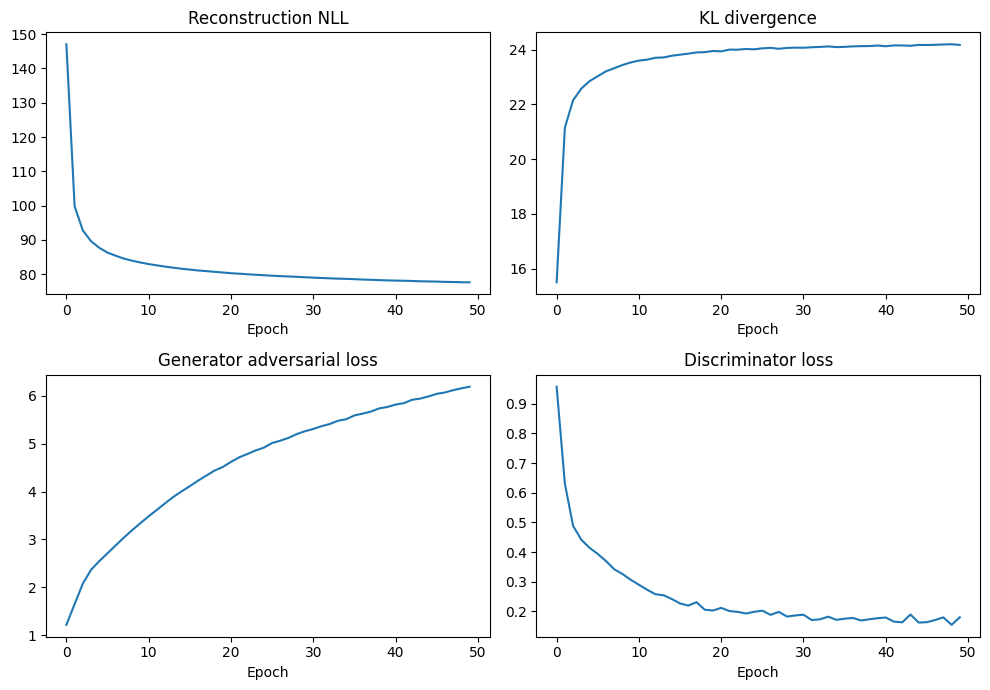

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, key, title in zip(
    axes.flat,
    ["reconstruction", "kl", "adversarial", "discriminator"],
    ["Reconstruction NLL", "KL divergence", "Generator adversarial loss", "Discriminator loss"],
):
    ax.plot([row[key] for row in history])
    ax.set(title=title, xlabel="Epoch")
plt.tight_layout(); plt.show()


## Inspect reconstructions and prior samples

Reconstructions show how well the encoder-decoder retains input details. Prior samples test generation from `z ~ N(0, I)`. The adversarial objective encourages realism, but a simple pixel discriminator does not guarantee perceptual quality or diversity.

Mean discriminator real score: 0.754; reconstruction score: 0.019


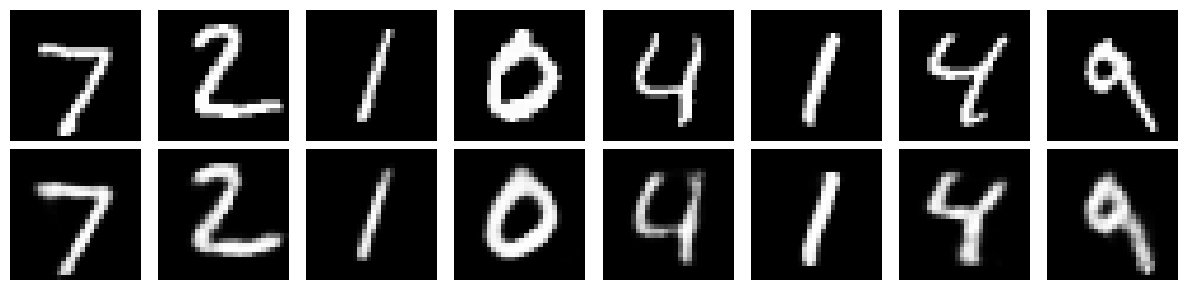

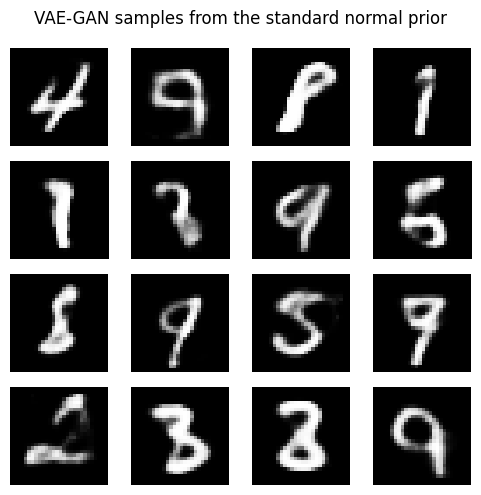

In [10]:
x = sample_batch(test_loader)[:8]
vae_gan.eval(); image_disc.eval()
with torch.no_grad():
    mu, logvar = vae_gan.encode(x)
    reconstruction = vae_gan.decode(vae_gan.reparameterize(mu, logvar))
    prior_samples = vae_gan.decode(torch.randn(16, vae_gan.latent_dim, device=device))
    real_score = torch.sigmoid(image_disc(x)).mean().item()
    recon_score = torch.sigmoid(image_disc(reconstruction)).mean().item()
print(f"Mean discriminator real score: {real_score:.3f}; reconstruction score: {recon_score:.3f}")

fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(x[i, 0].cpu(), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstruction[i, 0].cpu(), cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_ylabel("Input"); axes[1, 0].set_ylabel("Reconstruction")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, prior_samples):
    ax.imshow(image[0].cpu(), cmap="gray"); ax.axis("off")
plt.suptitle("VAE-GAN samples from the standard normal prior")
plt.tight_layout(); plt.show()
